# Unsupervised Learning

## Import

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

## Preprocess

Le but de cette division nous permet de prendre le CSV initial et d'en normaliser les données afin de pouvoir les faire analyser par l'IA plus efficacement.

On va créer un nouveau CSV avec 3 colonnes : chiffre couleur et phrase(symptome)

Le but va être de séparer les données du CSV inital qui ne possède pas de labals. Pour ceci, on va séparer les données aux virgules.
On enlève les guillemets qui ne sont pas toujours présente pour n'avoir que le symptôme propre sans avoir d'élément parasites.

In [62]:
df = pd.DataFrame(columns=["chiffre", "couleur", "phrase"])

with open("Student_Dataset.csv", "r", encoding="utf-8") as fichier:

    for ligne in fichier:
        ligne = ligne.strip()

        chiffre, phrase = ligne.split(",", 1)

        if "0x000000" in phrase:
            couleur, symptome = phrase.split(",", 1)
            symptome = symptome.replace('"', "")
            df.loc[len(df)] = [chiffre, couleur, symptome]

        else :
            phrase = phrase.replace('"', "")
            df.loc[len(df)] = [chiffre, "", phrase]

df.to_csv("Nouveau_Dataset.csv", index=False)

## Vérification

Pour vérifier que tout à été bien ajouté correctement, on vérifie la longueur des trois colonnes.

Et qu'il n'y est pas de vide dans les colonnes chiffre et phrase

In [63]:
print("Longueur de la colonne chiffre :", len(df["chiffre"]))
print("Longueur de la colonne couleur :", len(df["couleur"]))
print("Longueur de la colonne phrase :", len(df["phrase"]))

for k in df["chiffre"]:
    if k == "" or k == None:
        print("Erreur de valeur")

for k in df["phrase"]:
    if k == "" or k == None:
        print("Erreur de valeur")

Longueur de la colonne chiffre : 1011
Longueur de la colonne couleur : 1011
Longueur de la colonne phrase : 1011


## TF-IDF Vectorizer

Pour pouvoir entrainer notre IA, on va trasformer tous les mots en vecteur, qui seront compréhensible par notre IA.

On obtient également le nombre de mots différents parmi les 1011 lignes composant le dataset.

Pour éviter d'être embetté par des mots non pertinents au problème, on vectorise en enlevant les stop-words(the, a ...) afin de ne garder que des mots relatifs aux symptomes.

In [64]:
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df["phrase"])
noms = vectorizer.get_feature_names_out()
print(X.shape)

(1011, 2135)


## TruncatedSVD

In [65]:
resultats = []

for n_comp in range(10, 101, 10):
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_reduced = svd.fit_transform(X)

    for k in range(2, 40):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_reduced)
        score = silhouette_score(X_reduced, kmeans.labels_)
        resultats.append((n_comp, k, score))

df_resultats = pd.DataFrame(resultats, columns=["n_components", "k", "silhouette"])

print(df_resultats)

meilleur = df_resultats.loc[df_resultats["silhouette"].idxmax()]
print("Meilleure combinaison (sans contrainte) :\n", meilleur)

svd_final = TruncatedSVD(n_components=10, random_state=42)
X_reduced_final = svd_final.fit_transform(X)
print("Variance expliquée avec 10 composantes :", svd_final.explained_variance_ratio_.sum())

     n_components   k  silhouette
0              10   2    0.097189
1              10   3    0.143042
2              10   4    0.170457
3              10   5    0.204947
4              10   6    0.183061
..            ...  ..         ...
375           100  35    0.054474
376           100  36    0.056862
377           100  37    0.056578
378           100  38    0.058869
379           100  39    0.057955

[380 rows x 3 columns]
Meilleure combinaison (sans contrainte) :
 n_components    10.00000
k               10.00000
silhouette       0.30411
Name: 8, dtype: float64
Variance expliquée avec 10 composantes : 0.08178656052937838


## Loss Function (Unsupervised)

Dans notre partie non supervisée, la fonction de perte (ou loss function) s'appelle l'inertie. Elle calcule la somme des distances au carré entre chaque point de donnée et le centre du cluster auquel il est assigné. L'algorithme KMeans cherche constamment à minimiser cette valeur à chaque itération pour rendre les groupes les plus compacts et homogènes possible. Concrètement, nous l'utilisons avec la Elbow Method pour identifier le nombre optimal de clusters, c'est-à-dire le point où la baisse de l'inertie commence à ralentir. Ainsi, une inertie plus faible garantit que les symptômes regroupés dans un même cluster partagent des similarités sémantiques fortes et médicalement cohérentes.

## Elbow Method (Inertias)

Ensuite, nous faisons la "Elbow Method" (Méthode du coude) afin de déterminer une zone de valeurs idéales pour trouver notre nombre de cluster le plus efficace.

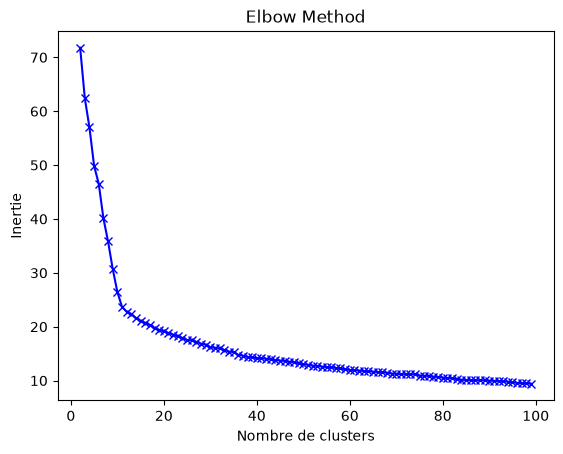

In [66]:

inertias = []
K = range(2, 100)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    inertias.append(kmeanModel.inertia_)

plt.plot(K, inertias, 'bx-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Inertie')
plt.title("Elbow Method")
plt.show()

Pour obtenir plus de précision, nous utilisons une silhouette score afin d'avoir une meilleure précision sur le nombre de clusters idéal pour regrouper nos différents mots.

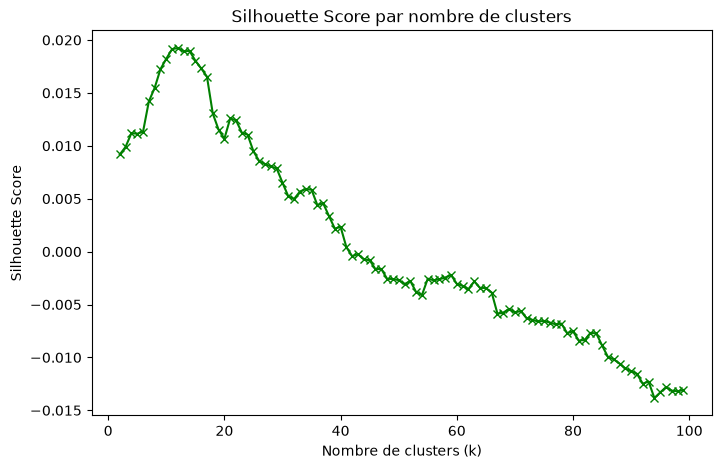

In [67]:
silhouette_scores = []
K2 = range(2, 100)

for k in K2:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    score = silhouette_score(X, kmeanModel.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K2, silhouette_scores, 'gx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title("Silhouette Score par nombre de clusters")
plt.show()

## Première conclusion

Grâce à notre vérifacation entre le nombre de components de TruncatedSVD et le nombre de clusters, on en vient à la conclusion que le meilleur assemblages est 10 components avec 10 clusters pour un score de 0.30411. 

On peut d'ailleurs vérifier ceci à l'aide de deux graphiques générés par une Elbow method et un silhouette score. Ils donnent chacun correlation sur 
ce résultat de 10 clusters.

Au delà de cela, on reconnait qu'avoir une dixaine de clusters ressemble à la réalité. Notre but est de grouper les symptomes, mais surtout de grouper les symptomes comme un médecin pourrait le faire. 

Or un médecin ne va pas faire 100/200 groupes de personnes qui serait absolument impossible à gérer facilement. 

La présence d'un pic entre 10 à 13 clusters de notre coefficient de silhouette va également dans notre sens, car le groupage des différents individus en une dixaine de groupe est cohérent avec ce qui peut se faire dans la réalité.

Nous décidons donc de partir sur ce nombre de clusters afin de regrouper nos symptômes de la manière la plus efficace et humaine possible.

## Clustering

On met donc notre nombre de cluster à 19, et on regroupe nos mots dans ceux-ci. 

On vérifie ensuite que nous obtenons un regroupement assez précis et adhéquat entre les éléments.

In [68]:
k_final = 10

kmeans = KMeans(n_clusters=k_final, random_state=42, n_init="auto").fit(X_reduced_final)

centres_originaux = svd_final.inverse_transform(kmeans.cluster_centers_)

for k in range(k_final):
    indices = centres_originaux[k].argsort()[-10:][::-1]
    print(f"**** Cluster n°{k} ****")
    for l in indices:
        print(noms[l])
    print()

**** Cluster n°0 ****
feels
ache
shoulder
arm
deep
makes
gives
lifting
reaching
weak

**** Cluster n°1 ****
ache
sore
long
deep
makes
foot
ankle
leg
knee
pushing

**** Cluster n°2 ****
chest
cough
breath
feel
feels
tight
night
short
feeling
like

**** Cluster n°3 ****
ear
pain
fever
cold
slight
sharp
left
right
feel
hearing

**** Cluster n°4 ****
feel
skin
pale
headaches
notice
looks
dizzy
weak
think
stand

**** Cluster n°5 ****
itchy
rash
new
raised
spots
hives
like
painful
welts
bumps

**** Cluster n°6 ****
felt
throat
nose
mild
day
cough
cold
headache
runny
sore

**** Cluster n°7 ****
ve
doctor
blood
night
weight
thirsty
feel
losing
feeling
sugar

**** Cluster n°8 ****
pain
head
feel
starts
throbbing
vision
like
gets
pressure
worse

**** Cluster n°9 ****
hot
blister
skin
red
small
feels
touched
tender
area
hand



In [ ]:
Z = linkage(kmeans.cluster_centers_, method='ward')

plt.figure(figsize=(10, 6))
plt.title("Dendrogramme des centres de clusters (Sont-ils éloignés ?)")
plt.ylabel("Distance (plus c'est bas, plus les clusters se ressemblent)")

# Affichage de l'arbre
dendrogram(Z, labels=[f"Cluster {i}" for i in range(k_final)], leaf_rotation=45)

plt.axhline(y=0.5, color='red', linestyle='--', linewidth=2, label='Seuil à 0.5')

plt.axhline(y=0.35, color='blue', linestyle='--', linewidth=2, label='Seuil à 0.35')

plt.axhline(y=(1-0.5-((0.5-0.35)/2)), color='black', linestyle='--', linewidth=2, label='Nouveau seuil')

plt.legend()

plt.show()

## Kmeans Modele

/tmp/ipykernel_21222/1397215337.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


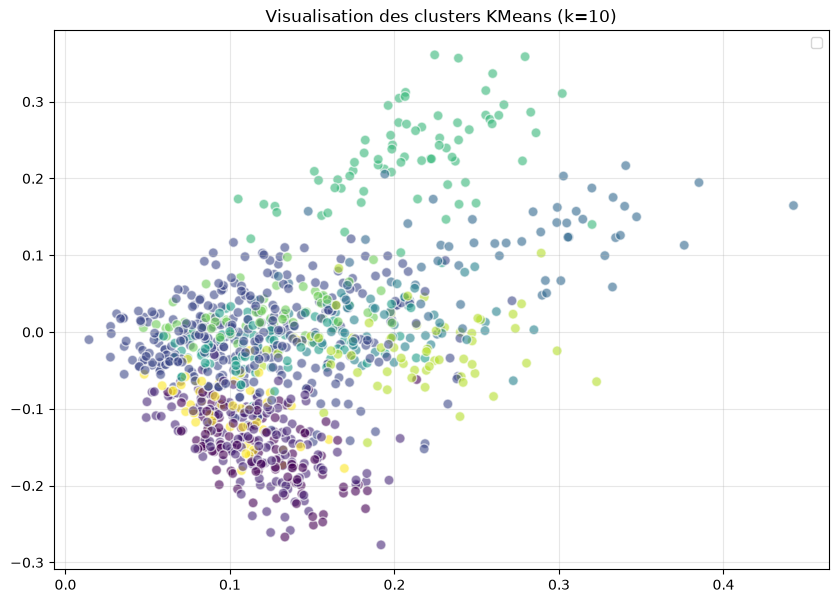

In [85]:
# Kmeans modele 
kmeans_final = KMeans(n_clusters=10, random_state=42, n_init="auto")
clusters = kmeans_final.fit_predict(X_reduced_final)

# Préparation de la visualisation 2D
x_axis = X_reduced_final[:, 0]
y_axis = X_reduced_final[:, 1]

plt.figure(figsize=(10, 7))

scatter = plt.scatter(x_axis, y_axis, c=clusters, cmap='viridis', alpha=0.6, edgecolors='w', s=50)
centres_2d = kmeans_final.cluster_centers_[:, :2]

plt.title("Visualisation des clusters KMeans (k=10)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Clustering Hiérarchique Agglomératif

Silhouette Score (Agglomerative) : 0.2821


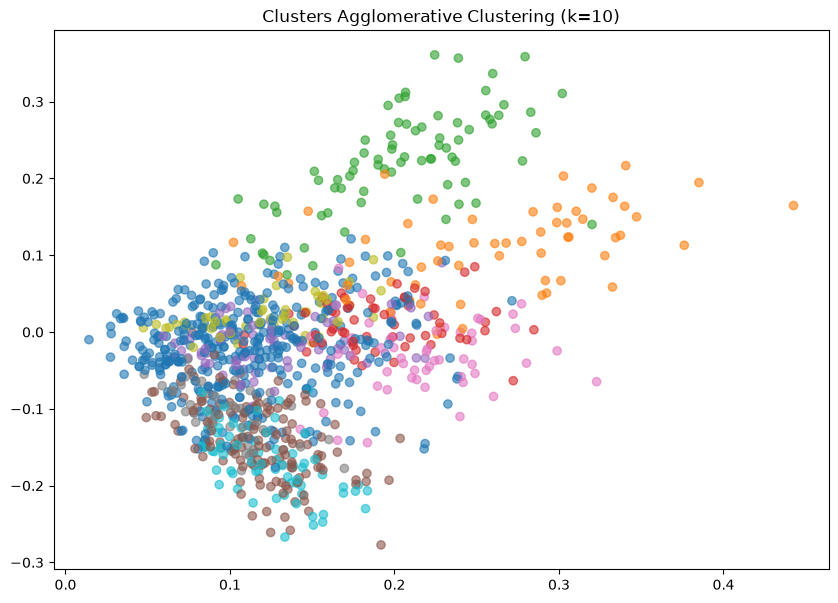

In [84]:
# Créer un modèle avec 10 clusters
modele_agglo = AgglomerativeClustering(n_clusters=10, linkage='ward')

# Entrainement du modèle
labels_agglo = modele_agglo.fit_predict(X_reduced_final)

score = silhouette_score(X_reduced_final, labels_agglo)
print(f"Silhouette Score (Agglomerative) : {score:.4f}")

plt.figure(figsize=(10, 7))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_agglo, cmap='tab10', alpha=0.6)
plt.title("Clusters Agglomerative Clustering (k=10)")
plt.show()

## Gausse Mélange Modèle

Silhouette Score (GMM) : 0.2350


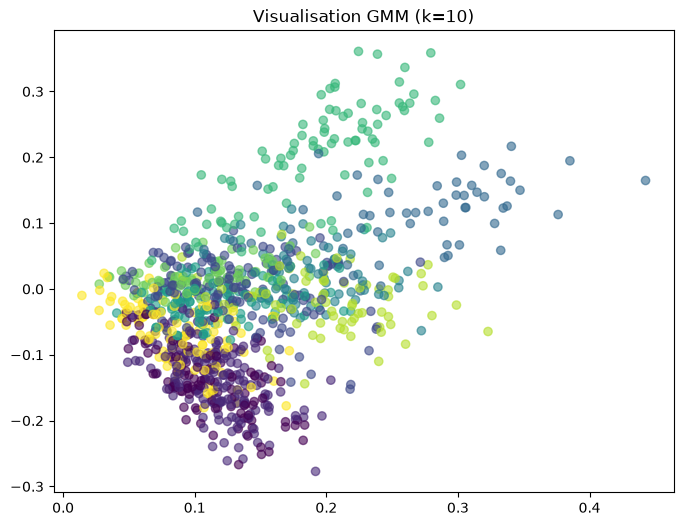

In [71]:
# GMM Modele (Gausse Melange Modele)
gmm = GaussianMixture(n_components=10, random_state=42).fit(X_reduced_final)
labels_gmm = gmm.predict(X_reduced_final)

print(f"Silhouette Score (GMM) : {silhouette_score(X_reduced_final, labels_gmm):.4f}")
plt.figure(figsize=(8, 6))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_gmm, cmap='viridis', alpha=0.6)
plt.title("Visualisation GMM (k=10)")
plt.show()

## DBSCAN


DBSCAN : 13 clusters trouvés, 391 points de bruit


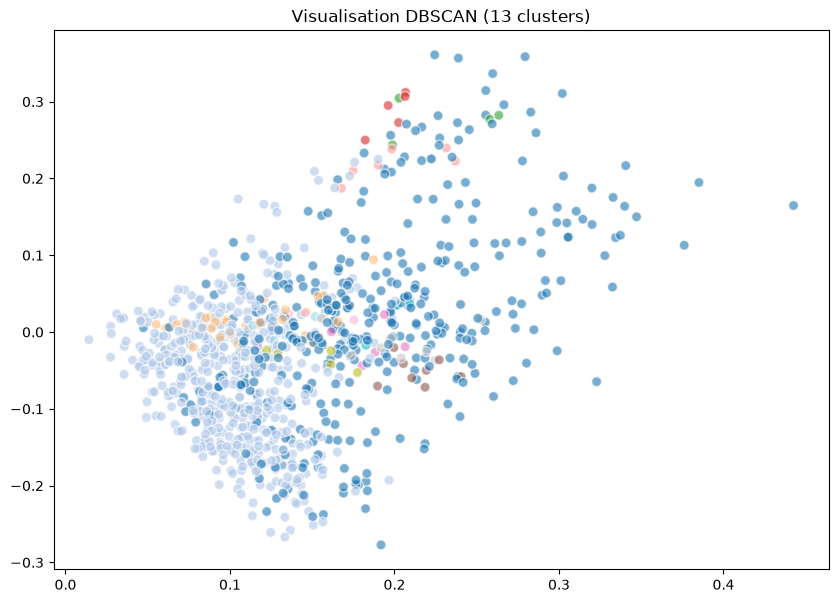

In [83]:
# Modèle dbscan
dbscan = DBSCAN(eps=0.1, min_samples=4)
labels_dbscan = dbscan.fit_predict(X_reduced_final)

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)
print(f"DBSCAN : {n_clusters} clusters trouvés, {n_noise} points de bruit")

plt.figure(figsize=(10, 7))
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_dbscan, cmap='tab20', alpha=0.6, edgecolors='w', s=50)
plt.title(f"Visualisation DBSCAN ({n_clusters} clusters)")
plt.show()

## comparaison 4 modèles


In [ ]:
modeles = {"KMeans": clusters, "Agglomerative": labels_agglo, "GMM": labels_gmm, "DBSCAN": labels_dbscan}
print("Comparaison des modèles de clustering :\n")

for nom, labels in modeles.items():
    # dbscan considère -1 comme du bruit et donc on l'exclut du calcul
    if nom == "DBSCAN":
        mask = labels != -1
        X_calc = X_reduced_final[mask]
        labels_calc = labels[mask]

        nb_clusters = len(set(labels)) - 1
        nb_bruit = sum(labels == -1)

    else:
        X_calc = X_reduced_final
        labels_calc = labels
        nb_clusters = len(set(labels))
        nb_bruit = 0

    # Le score de silhouette nécessite au moins 2 clusters
    if nb_clusters > 1:
        score = silhouette_score(X_calc, labels_calc)
    else:
        score = 0.0

    print(f"{nom:<15} | Score : {score:.4f} " f"| Clusters : {nb_clusters} " f"| Bruit : {nb_bruit}")

Comparaison des modèles de clustering :

KMeans          | Score : 0.3041 | Clusters : 10 | Bruit : 0
Agglomerative   | Score : 0.2821 | Clusters : 10 | Bruit : 0
GMM             | Score : 0.2350 | Clusters : 10 | Bruit : 0
DBSCAN          | Score : 0.0245 | Clusters : 13 | Bruit : 391
